# BDA500 Project 1: Regression — Predicting Student Math Scores

**Team members:** _Lionael Surya, Margil Parekh, Chehoon Shin_
**Dataset:** _Students Performance in Exams (Kaggle, spscientist)_
**Due:** October 14, 2026, 11:59 PM ET

**This notebook:** Sections 0–3 (Setup, Problem Framing, Data Understanding, EDA) — **Contributor: Lionael Surya**

## 0. Setup

**Question:** Which libraries, paths, target, identifiers, dates, leakage columns, and random settings are required?

In [1]:
# Contributor: Lionael Surya — Section 0 Setup
import warnings, json
# %pip install plotly seaborn joblib -q   # uncomment if running in a fresh environment
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# Paths
DATA_PATH = Path("../StudentsPerformance.csv")
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Column roles (justified in Section 2.2)
TARGET = "math score"
NUM_FEATURES = ["reading score", "writing score"]
CAT_FEATURES = ["gender", "race/ethnicity", "parental level of education",
                "lunch", "test preparation course"]
ID_COLS, DATE_COLS, LEAKAGE_COLS = [], [], []   # none exist in this dataset

print("Libraries loaded")

Libraries loaded


## 1. Problem Framing

**Question:** What continuous value will be predicted in supervised learning?

**Supervised question:** Given a student's reading and writing scores, demographic background, and whether they completed a test-preparation course, what **math score (0–100)** will they achieve?

| Item | Definition |
|---|---|
| **Target (y)** | `math score` — continuous, 0–100 |
| **Features (X)** | `reading score`, `writing score` (numeric); `gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course` (categorical) |
| **Unit of analysis** | One student |
| **Data source** | [Students Performance in Exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams), Kaggle (spscientist), 1,000 students |
| **Intended users** | School counsellors and academic-support staff |

**Practical value.** Literacy assessments are often completed before, or separately from, math assessment. An accurate math-score estimate lets a school flag students likely to fall below a threshold (e.g., < 50) and assign tutoring or test-prep seats *before* the exam. The model also shows which factors that can be acted on (e.g., test-prep completion) are associated with higher scores, which can support a decision to fund more prep courses.

**Risks and limitations.**
- **Fairness:** `race/ethnicity`, `gender`, and `lunch` (an income proxy) are sensitive attributes. Predictions must only be used to *direct support toward* students, never to restrict opportunities.
- **Correlation ≠ causation:** completing test prep may reflect motivation rather than the course's own effect.
- **Timing assumption:** reading and writing scores must be available before math is assessed; otherwise the early-warning value is reduced.
- **Sample size and generalisability:** 1,000 rows is below the preferred 5,000–10,000. The dataset is the full public release (no sampling); it comes from a single unnamed source with no school or date information, so results may not transfer to other schools or years.

In [2]:
# Contributor: Lionael Surya — Section 1 target overview
df_raw = pd.read_csv(DATA_PATH)
print(f"Target: '{TARGET}'  |  n = {df_raw[TARGET].size}")
df_raw[TARGET].describe().round(2)

Target: 'math score'  |  n = 1000


count    1000.00
mean       66.09
std        15.16
min         0.00
25%        57.00
50%        66.00
75%        77.00
max       100.00
Name: math score, dtype: float64

## 2.1 Load and Inspect

**Question:** What are the head, shape, structure, data types, summary statistics, and missing-value counts?

In [3]:
# Contributor: Lionael Surya — Section 2.1 Load and Inspect
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [5]:
print("Data types:")
print(df.dtypes.to_string())
print("\nNumeric summary:")
display(df.describe().T.round(2))
print("Categorical summary:")
display(df.describe(include="object").T)

Data types:
gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.09,15.16,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.17,14.60,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.05,15.20,10.0,57.75,69.0,79.0,100.0


Categorical summary:


,count,unique,top,freq
gender,1000,2,female,518
race/ethnicity,1000,5,group C,319
parental level of education,1000,6,some college,226
lunch,1000,2,standard,645
test preparation course,1000,2,none,642


In [6]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


**Findings.**
- 1,000 rows × 8 columns: 5 categorical (text) and 3 numeric (integer scores, 0–100).
- **No missing values** in any column, so imputation is not needed for this data. A `SimpleImputer` can still be kept in the pipeline as a safeguard for future data.
- Mean scores: math 66.1, reading 69.2, writing 68.1, each with a standard deviation of about 15. Math has the lowest mean and the widest range (0–100).

## 2.2 Column Roles and Cleaning

**Question:** Which columns are numeric, categorical, identifiers, dates, target, or leakage, and how are duplicates/removals handled?

In [7]:
# Contributor: Lionael Surya — Section 2.2 Column Roles
role_notes = {
    "math score": ("Target", "Continuous 0–100; the value we predict"),
    "reading score": ("Numeric feature", "Literacy score; assumed known before math is assessed"),
    "writing score": ("Numeric feature", "Literacy score; assumed known before math is assessed"),
    "gender": ("Categorical (nominal, binary)", "Sensitive attribute — monitor for bias"),
    "race/ethnicity": ("Categorical (nominal, 5 levels)", "Anonymised groups A–E; sensitive attribute"),
    "parental level of education": ("Categorical (ordered, 6 levels)", "Natural order exists; one-hot chosen (see below)"),
    "lunch": ("Categorical (nominal, binary)", "Free/reduced lunch is a proxy for household income"),
    "test preparation course": ("Categorical (nominal, binary)", "Intervention a school can act on"),
}
roles = pd.DataFrame(
    [(c, str(df[c].dtype), df[c].nunique(), *role_notes[c]) for c in df.columns],
    columns=["column", "dtype", "n_unique", "role", "notes"])
roles

,column,dtype,n_unique,role,notes
0,gender,str,2,"Categorical (nominal, binary)",Sensitive attribute — monitor for bias
1,race/ethnicity,str,5,"Categorical (nominal, 5 levels)",Anonymised groups A–E; sensitive attribute
2,parental level of education,str,6,"Categorical (ordered, 6 levels)",Natural order exists; one-hot chosen (see below)
3,lunch,str,2,"Categorical (nominal, binary)",Free/reduced lunch is a proxy for household in...
4,test preparation course,str,2,"Categorical (nominal, binary)",Intervention a school can act on
5,math score,int64,81,Target,Continuous 0–100; the value we predict
6,reading score,int64,72,Numeric feature,Literacy score; assumed known before math is a...
7,writing score,int64,77,Numeric feature,Literacy score; assumed known before math is a...


In [8]:
for c in CAT_FEATURES:
    print(f"{c}: {df[c].value_counts().to_dict()}")

gender: {'female': 518, 'male': 482}
race/ethnicity: {'group C': 319, 'group D': 262, 'group B': 190, 'group E': 140, 'group A': 89}
parental level of education: {'some college': 226, "associate's degree": 222, 'high school': 196, 'some high school': 179, "bachelor's degree": 118, "master's degree": 59}
lunch: {'standard': 645, 'free/reduced': 355}
test preparation course: {'none': 642, 'completed': 358}


In [9]:
# Duplicates and leakage checks
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows with identical features (X) but different target:",
      df.duplicated(subset=NUM_FEATURES + CAT_FEATURES).sum())
print("Identifier columns:", ID_COLS or "none")
print("Date columns:", DATE_COLS or "none")
print("Leakage columns:", LEAKAGE_COLS or "none")

# Out-of-range check (scores must be 0–100)
print("\nScores outside 0–100:",
      ((df[[TARGET] + NUM_FEATURES] < 0) | (df[[TARGET] + NUM_FEATURES] > 100)).sum().sum())

# Extreme low math scores (kept, examined as outliers)
df[df[TARGET] < 20]

Exact duplicate rows: 0
Rows with identical features (X) but different target: 4
Identifier columns: none
Date columns: none
Leakage columns: none

Scores outside 0–100: 0


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
787,female,group B,some college,standard,none,19,38,32
980,female,group B,high school,free/reduced,none,8,24,23


**Column roles.**
- **Target:** `math score`.
- **Numeric features:** `reading score`, `writing score`.
- **Categorical features:** `gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course`.
- **Identifiers / dates:** none. The dataset has no student ID or timestamp. As a result, time-based splitting and per-student grouping are not possible.
- **Leakage:** none under this framing. Leakage **would** be introduced by any derived total or average that includes the math score (e.g., `average score`), so no such feature is created. Reading and writing are treated as legitimate predictors under the assumption that they are measured before or independently of math.

**Cleaning decisions.**
- **Duplicates:** 0 exact duplicates, so no rows are removed. 4 rows share identical features with another row but have a different math score. These are real, distinct students, and they are kept.
- **Removed rows / columns:** none. All scores lie within 0–100.
- **Low-score outliers** (e.g., the student with math = 0, reading = 17, writing = 10) are consistent across all three subjects, which suggests genuine low performance rather than data-entry errors. They are **kept**, and their effect is examined in the residual analysis (Section 6.5).
- **Encoding plan (for Section 5):** one-hot encoding for all categoricals. `parental level of education` has a natural order, but the gaps between levels are not equal (and "some college" vs "associate's" is ambiguous), so one-hot avoids imposing a linear spacing.

## 3.1 Histograms and Boxplots

**Question:** What do important numeric distributions and boxplots reveal about spread, skewness, and outliers?

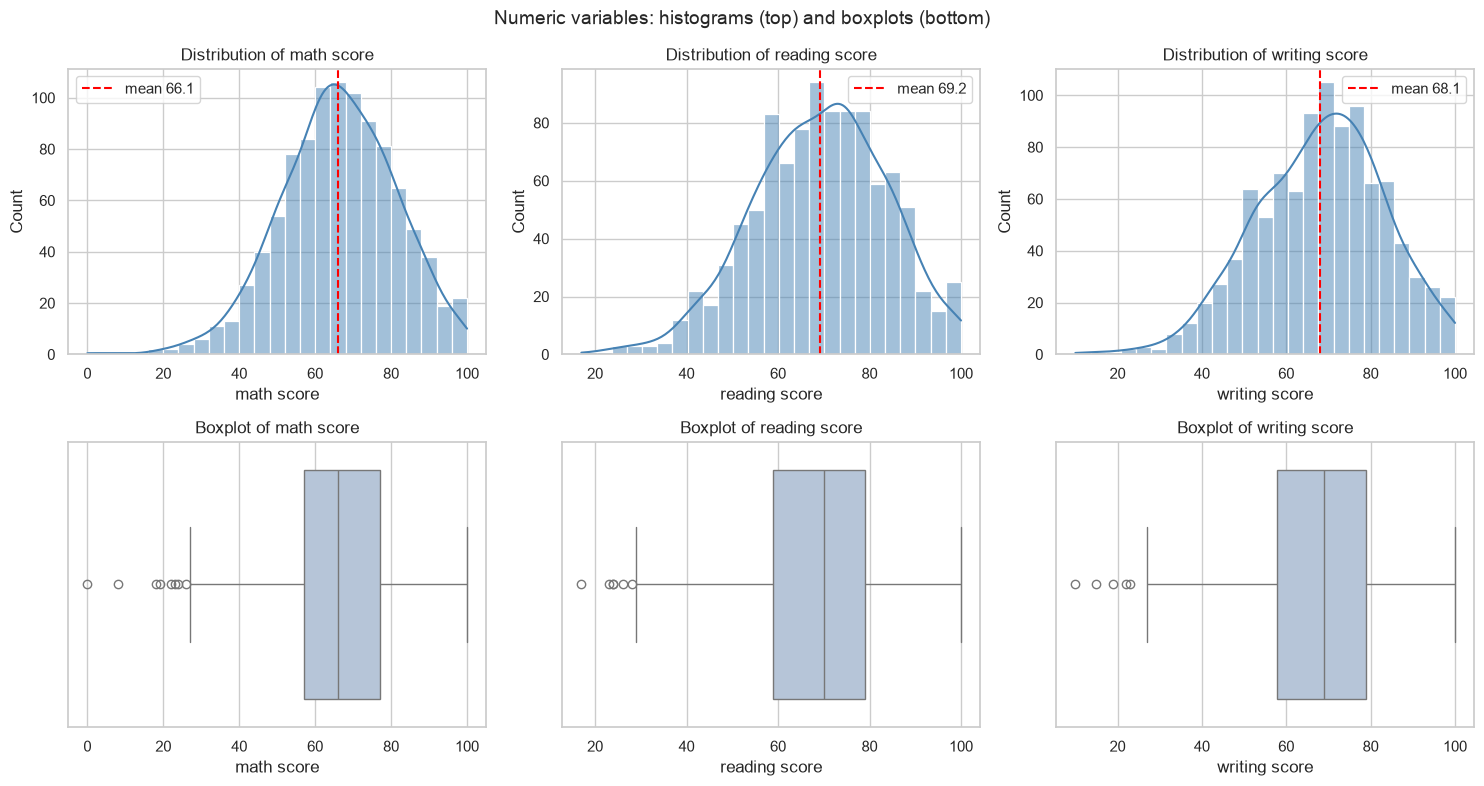

In [10]:
# Contributor: Lionael Surya — Section 3.1 Distributions
scores = [TARGET] + NUM_FEATURES
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(scores):
    sns.histplot(df[col], bins=25, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].axvline(df[col].mean(), color="red", ls="--", label=f"mean {df[col].mean():.1f}")
    axes[0, i].set_title(f"Distribution of {col}")
    axes[0, i].legend()
    sns.boxplot(x=df[col], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_title(f"Boxplot of {col}")
fig.suptitle("Numeric variables: histograms (top) and boxplots (bottom)", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "3_1_hist_box.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

pd.DataFrame({
    "skewness": df[scores].skew().round(2),
    "iqr_outliers": [len(iqr_outliers(df[c])) for c in scores],
    "outlier_values": [sorted(iqr_outliers(df[c]).tolist()) for c in scores],
    "n_at_100": [(df[c] == 100).sum() for c in scores],
})

,skewness,iqr_outliers,outlier_values,n_at_100
math score,-0.28,8,"[0, 8, 18, 19, 22, 23, 24, 26]",7
reading score,-0.26,6,"[17, 23, 24, 24, 26, 28]",17
writing score,-0.29,5,"[10, 15, 19, 22, 23]",14


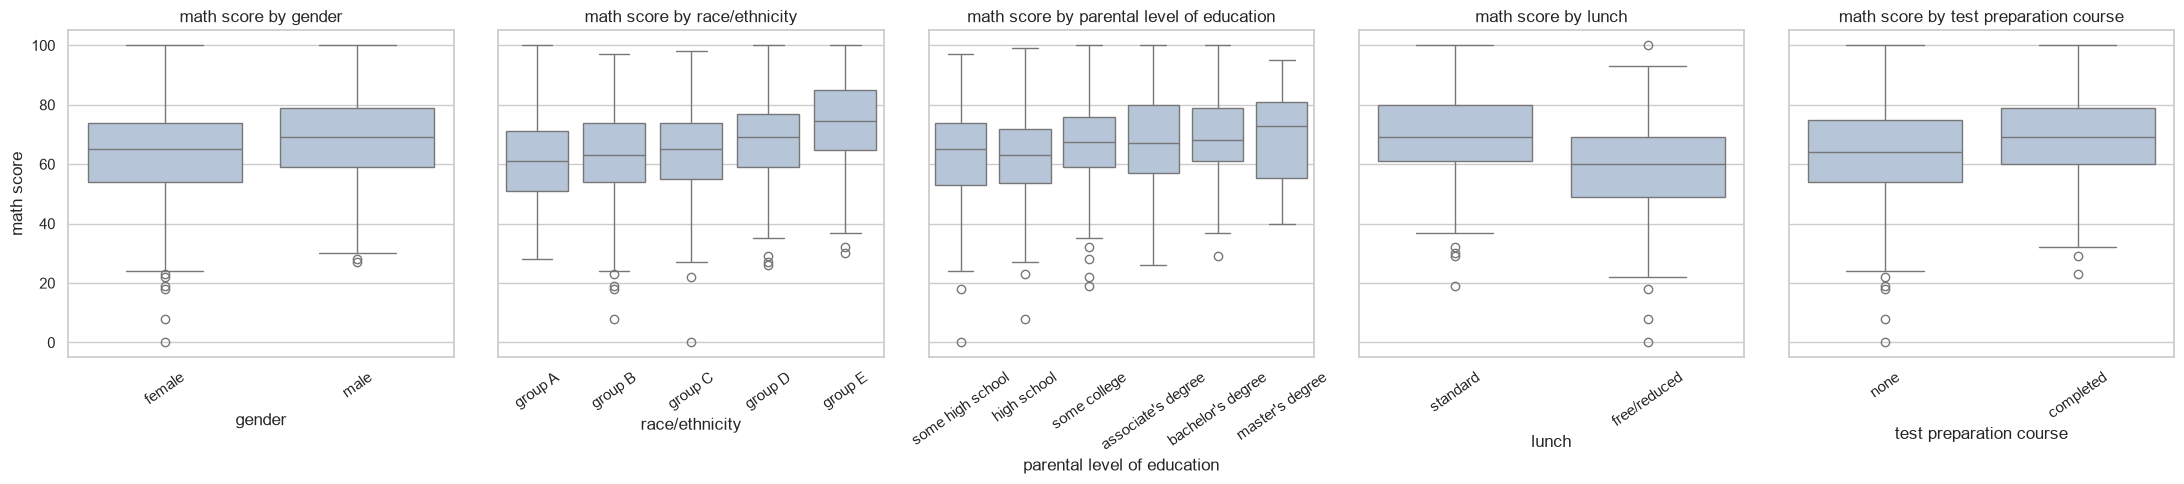

In [12]:
# Target distribution across each categorical feature
fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharey=True)
edu_order = ["some high school", "high school", "some college",
             "associate's degree", "bachelor's degree", "master's degree"]
orders = {"parental level of education": edu_order,
          "race/ethnicity": sorted(df["race/ethnicity"].unique())}
for ax, col in zip(axes, CAT_FEATURES):
    sns.boxplot(data=df, x=col, y=TARGET, order=orders.get(col), ax=ax, color="lightsteelblue")
    ax.set_title(f"{TARGET} by {col}")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig(FIG_DIR / "3_1_target_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.**
- All three scores are **roughly normal with a mild left skew** (skewness ≈ −0.26 to −0.29). The left tail is a small group of very low scorers. This skew is mild, so no transformation of the target is needed.
- **Outliers (IQR rule):** math 8, reading 6, writing 5, all on the **low** side (e.g., math = 0, 8, 18). No high-side outliers. A few students hit the 100 ceiling (7 in math, 17 in reading), so the scale is slightly capped at the top.
- The spread is similar across subjects (IQR ≈ 20 points), so the numeric features are on comparable scales. They will still be standardised in Section 5.
- **By category:** standard lunch (mean higher by ~11 points), completed test prep (~+5.6), male (~+5.1), and group E (~+10 vs group A) show higher math scores. Parental education shows a weaker, non-linear pattern: "high school" is the lowest group, not "some high school".

## 3.2 Correlations and Target Relationships

**Question:** Which numeric variables correlate, and how do at least two important predictors relate to the target?

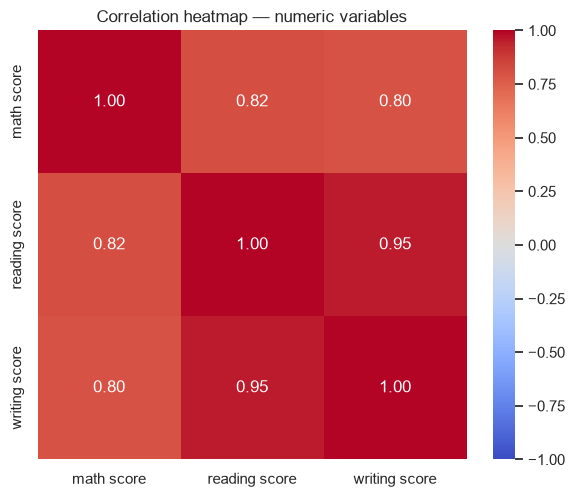

In [13]:
# Contributor: Lionael Surya — Section 3.2 Correlations
corr = df[scores].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap — numeric variables")
plt.tight_layout()
plt.savefig(FIG_DIR / "3_2_corr_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

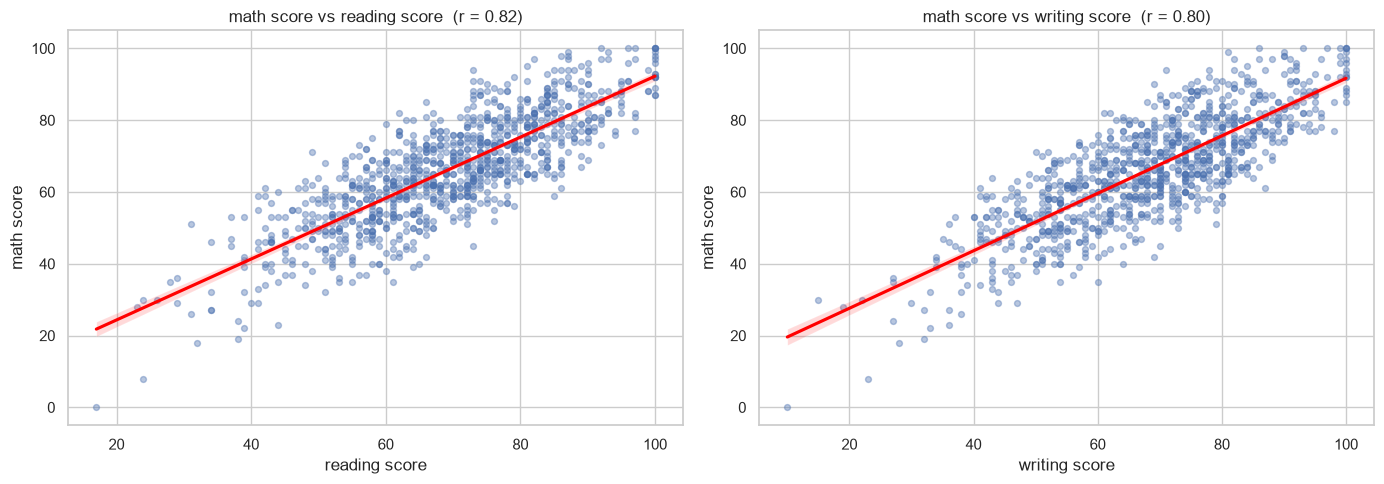

In [14]:
# Predictor vs target: reading and writing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, NUM_FEATURES):
    sns.regplot(data=df, x=col, y=TARGET, ax=ax, scatter_kws={"alpha": 0.4, "s": 18},
                line_kws={"color": "red"})
    ax.set_title(f"{TARGET} vs {col}  (r = {df[col].corr(df[TARGET]):.2f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "3_2_predictors_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

,max_gap_points
feature,
race/ethnicity,12.2
lunch,11.1
parental level of education,7.6
test preparation course,5.6
gender,5.1


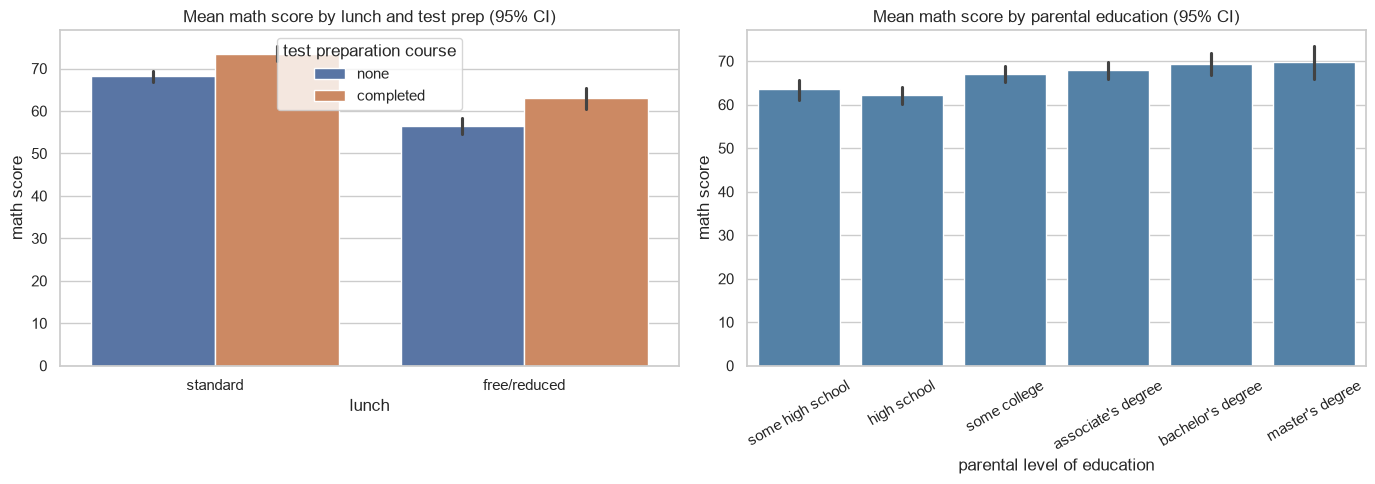

In [15]:
# Mean math score and gap per category
rows = []
for col in CAT_FEATURES:
    g = df.groupby(col)[TARGET].agg(["mean", "count"])
    for level, r in g.iterrows():
        rows.append((col, level, round(r["mean"], 1), int(r["count"])))
cat_means = pd.DataFrame(rows, columns=["feature", "level", "mean_math", "n"])
gaps = (cat_means.groupby("feature")["mean_math"].agg(lambda s: s.max() - s.min())
        .sort_values(ascending=False).rename("max_gap_points"))
display(gaps.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x="lunch", y=TARGET, hue="test preparation course", ax=axes[0], errorbar=("ci", 95))
axes[0].set_title("Mean math score by lunch and test prep (95% CI)")
sns.barplot(data=df, x="parental level of education", y=TARGET, order=edu_order, ax=axes[1],
            color="steelblue", errorbar=("ci", 95))
axes[1].set_title("Mean math score by parental education (95% CI)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "3_2_categorical_effects.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.**
- **Strong positive relationships with the target:** reading (r = 0.82) and writing (r = 0.80). Both relationships look **linear** with roughly constant spread, which supports Linear/Ridge regression as a good fit.
- **Multicollinearity:** reading and writing are correlated at **r = 0.95**, so they carry nearly the same information. Plain linear regression coefficients for these two features may be unstable. This is the main motivation for **Ridge (L2) regularisation** in Section 6.
- **Categorical effects (largest gap in mean math score):** race/ethnicity ≈ 12 points (A → E), lunch ≈ 11, parental education ≈ 8, test prep ≈ 5.6, gender ≈ 5.1. The lunch and test-prep effects add up: standard lunch + completed prep is the highest-scoring group.

## 3.3 Possible Cluster Structure

**Question:** Does a scatterplot of two important features reveal possible grouping, overlap, or outliers?

        math score  reading score  writing score
gender                                          
female        63.6           72.6           72.5
male          68.7           65.5           63.3


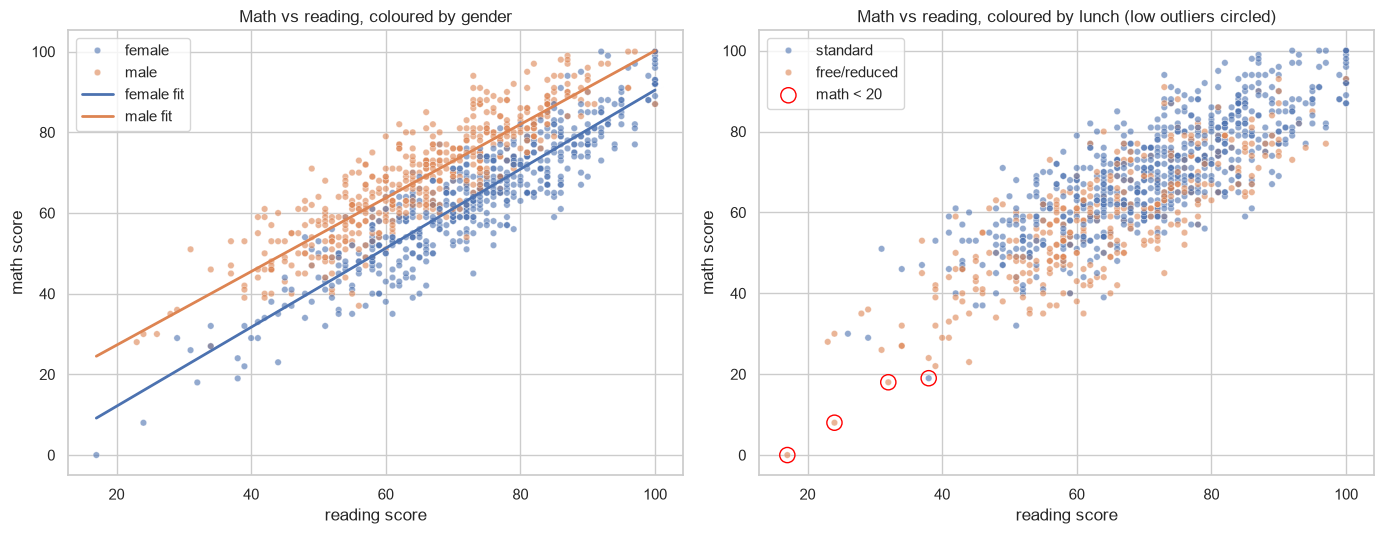

In [16]:
# Contributor: Lionael Surya — Section 3.3 Grouping
print(df.groupby("gender")[scores].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df, x="reading score", y=TARGET, hue="gender", alpha=0.6, s=22, ax=axes[0])
for g, color in zip(["female", "male"], sns.color_palette()[:2]):
    sub = df[df["gender"] == g]
    m, b = np.polyfit(sub["reading score"], sub[TARGET], 1)
    xs = np.linspace(df["reading score"].min(), 100, 50)
    axes[0].plot(xs, m * xs + b, color=color, lw=2, label=f"{g} fit")
axes[0].set_title("Math vs reading, coloured by gender")
axes[0].legend()

sns.scatterplot(data=df, x="reading score", y=TARGET, hue="lunch", alpha=0.6, s=22, ax=axes[1])
low = df[df[TARGET] < 20]
axes[1].scatter(low["reading score"], low[TARGET], s=120, facecolors="none", edgecolors="red",
                label="math < 20")
axes[1].set_title("Math vs reading, coloured by lunch (low outliers circled)")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "3_3_grouping_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.**
- **Gender forms two parallel bands.** Females score higher in reading (72.6 vs 65.5) and writing (72.5 vs 63.3), but lower in math (63.6 vs 68.7). **At the same reading score, a male student scores noticeably higher in math.** The fitted lines are offset by about 16 points at low reading scores, narrowing to about 10 near 100. That narrowing hints at a gender × reading **interaction**, which the interaction terms in Polynomial Regression can capture. This means `gender` adds information beyond reading/writing and should stay in the model. It also explains why gender's effect looks small on its own but matters once reading is controlled for.
- **Lunch groups overlap heavily** without clear separation. Free/reduced-lunch students are shifted toward the lower-left but spread across the whole range, so lunch shifts the average without forming a distinct cluster.
- **No distinct natural clusters** appear. The data forms one continuous elongated cloud along the reading–math diagonal.
- **Outliers:** the 4 students with math < 20 sit at the bottom-left, low in *all* subjects. They follow the overall trend rather than contradicting it, which supports keeping them. They are likely to produce the largest absolute residuals in the model.

### Summary for modelling (handoff to Sections 5–6)
| Decision | Choice | Reason |
|---|---|---|
| Missing values | None present; optional `SimpleImputer` safeguard | 0 missing in all columns |
| Rows removed | None | 0 duplicates; outliers are genuine |
| Numeric scaling | `StandardScaler` on reading, writing | Required for Ridge; puts features on a common scale |
| Categorical encoding | `OneHotEncoder(drop="first", handle_unknown="ignore")` on all 5 | Nominal categories; parental-education gaps are not equal |
| Key risk | Reading–writing collinearity (r = 0.95) | Favours Ridge; interpret linear coefficients with care |